In [56]:
from langgraph.graph import StateGraph
from langchain_ollama import ChatOllama
from typing import TypedDict
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langgraph.constants import START, END

In [57]:
model= ChatOllama(
    model="qwen2.5-coder:3b", temperature=0.3
)

In [58]:
# create parser 
parser= StrOutputParser()

In [59]:
# define state
class QuizState(TypedDict):
    topic: str
    report: str
    qa: str
    top_qa: str

In [60]:
# create graph 

graph= StateGraph(QuizState)

In [61]:
def gen_report(state: QuizState) -> QuizState:

    topic= state["topic"]
    prompt= PromptTemplate(
        template="Create a detailed report on the given topic -> {topic}",
        input_variables=["topic"]
    )

    chain= prompt | model | parser

    result= chain.invoke({"topic": topic})

    state["report"]= result

    return state


In [62]:
def gen_qa(state: QuizState) -> QuizState:

    report= state["report"]

    prompt= PromptTemplate(
        template="create a 5-6 question answer based on the provided report \n\n report->{report}",
        input_variables=["report"]
    )

    chain= prompt | model | parser

    result= chain.invoke({"report": report})

    state["qa"]= result

    return state

In [63]:
def gen_top_qa(state: QuizState) -> QuizState:

    qa= state["qa"]

    prompt= PromptTemplate(
        template="Find the best question answer pair from the list of question answers on the basis of importance \n\n question answers ->{qa}",
        input_variables=["qa"]
    )

    chain= prompt | model | parser

    result= chain.invoke({"qa": qa})

    state["top_qa"]= result

    return state

In [64]:
# creata nodes
graph.add_node("gen_report",gen_report)
graph.add_node("gen_qa",gen_qa)
graph.add_node("gen_top_qa",gen_top_qa)


# create edges 
graph.add_edge(START,"gen_report")
graph.add_edge("gen_report","gen_qa")
graph.add_edge("gen_qa","gen_top_qa")
graph.add_edge("gen_top_qa", END)

In [65]:
# compile graph 
workflow= graph.compile()

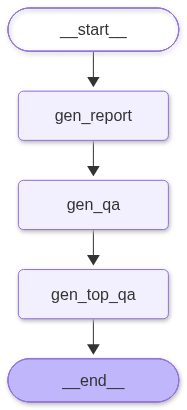

In [66]:
# graph visualization 
from IPython.display import Image, display
display(Image(workflow.get_graph().draw_mermaid_png()))

In [67]:
initial_state= {'topic': "Rise of AI in INDIA"}

final_state= workflow.invoke(initial_state)

print(final_state)

{'topic': 'Rise of AI in INDIA', 'report': 'The rise of artificial intelligence (AI) in India has been a significant development in recent years, driven by a combination of technological advancements, policy support, and a growing demand for AI-driven solutions. This report aims to provide a comprehensive overview of the current state of AI in India, its potential impact, and the challenges that lie ahead.\n\n### 1. Introduction\n\nIndia has been at the forefront of AI development, with a growing focus on AI as a key driver of economic growth and innovation. The country has a large and diverse workforce, a strong academic infrastructure, and a growing ecosystem of startups and research institutions dedicated to AI. The government has also been actively promoting AI through various initiatives and policies.\n\n### 2. Current State of AI in India\n\n#### 2.1 AI Adoption\n\nIndia has seen a significant increase in AI adoption across various sectors, including healthcare, finance, transpor

In [68]:
print(final_state["topic"])
print(final_state["report"])
print(final_state["qa"])
print(final_state["top_qa"])

Rise of AI in INDIA
The rise of artificial intelligence (AI) in India has been a significant development in recent years, driven by a combination of technological advancements, policy support, and a growing demand for AI-driven solutions. This report aims to provide a comprehensive overview of the current state of AI in India, its potential impact, and the challenges that lie ahead.

### 1. Introduction

India has been at the forefront of AI development, with a growing focus on AI as a key driver of economic growth and innovation. The country has a large and diverse workforce, a strong academic infrastructure, and a growing ecosystem of startups and research institutions dedicated to AI. The government has also been actively promoting AI through various initiatives and policies.

### 2. Current State of AI in India

#### 2.1 AI Adoption

India has seen a significant increase in AI adoption across various sectors, including healthcare, finance, transportation, and manufacturing. Accordi